In [1]:
import sqlite3
import pandas as pd

con = sqlite3.connect('data/olist.db')

In [2]:
def run(sql):
    return pd.read_sql(sql, con)

## Part 1: baseline features

In [3]:
run("""
WITH single_seller_orders AS (
    SELECT i.order_id,
           MIN(i.seller_id) AS seller_id,
           COUNT(*) AS n_items,
           SUM(i.price) AS total_price,
           SUM(i.freight_value) AS total_freight,
           SUM(p.product_weight_g) AS total_weight_g,
           MIN(p.product_category_name) AS category
    FROM order_items i
    JOIN products p ON i.product_id = p.product_id
    GROUP BY i.order_id
    HAVING COUNT(DISTINCT i.seller_id) = 1
)
SELECT o.order_id,
       o.order_purchase_timestamp,
       c.customer_state,
       s.seller_state,
       x.n_items, x.total_price, x.total_freight, x.total_weight_g, x.category,
       CAST(strftime('%m', o.order_purchase_timestamp) AS INTEGER) AS month,
       CAST(strftime('%w', o.order_purchase_timestamp) AS INTEGER) AS weekday,
       JULIANDAY(o.order_estimated_delivery_date) - JULIANDAY(o.order_purchase_timestamp) AS estimated_days,
       CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END AS is_late
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN single_seller_orders x ON x.order_id = o.order_id
JOIN sellers s ON s.seller_id = x.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2017-01' AND '2018-08'
ORDER BY o.order_purchase_timestamp;
""")

,order_id,order_purchase_timestamp,customer_state,seller_state,n_items,total_price,total_freight,total_weight_g,category,month,weekday,estimated_days,is_late
0,ec7a019261fce44180373d45b442d78f,2017-01-05 11:56:06,PR,PR,1,10.90,8.72,200.0,fashion_bolsas_e_acessorios,1,4,26.502708,0
1,b95a0a8bd30aece4e94e81f0591249d8,2017-01-05 12:01:20,PR,PR,1,10.90,8.72,200.0,automotivo,1,4,38.499074,0
2,38bcb524e1c38c2c1b60600a80fc8999,2017-01-05 12:06:36,PR,PR,1,2.90,8.72,200.0,pet_shop,1,4,38.495417,0
3,7a18a504c1a4b32d883e68de2e1a7db0,2017-01-05 12:09:08,PR,PR,1,7.90,8.72,200.0,pet_shop,1,4,38.493657,0
4,6acecf438369055d9243e121045cca74,2017-01-05 12:11:23,PR,PR,1,9.90,8.72,200.0,pet_shop,1,4,38.492095,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
94926,52018484704db3661b98ce838612b507,2018-08-29 12:25:59,SP,SP,1,63.90,9.20,1500.0,brinquedos,8,3,4.481956,0
94927,0b223d92c27432930dfe407c6aea3041,2018-08-29 14:18:23,PR,PR,2,418.00,92.96,27100.0,moveis_cozinha_area_de_servico_jantar_e_jardim,8,3,5.403900,0
94928,168626408cb32af0ffaf76711caae1dc,2018-08-29 14:18:28,MG,MG,1,45.90,15.39,1614.0,beleza_saude,8,3,12.403843,0
94929,03ef5dedbe7492bdae72eec50764c43f,2018-08-29 14:52:00,SP,SP,1,24.90,8.33,450.0,artigos_de_festas,8,3,4.380556,0


In [4]:
sql = open("sql/orders_dataset.sql").read()
df = pd.read_sql(sql, con)
df.to_csv("data/orders_dataset.csv", index=False)

print(df.shape)
print(df["is_late"].mean())
print(df.isna().sum())

(94931, 13)
0.08220707671888003
order_id                       0
order_purchase_timestamp       0
customer_state                 0
seller_state                   0
n_items                        0
total_price                    0
total_freight                  0
total_weight_g                16
category                    1330
month                          0
weekday                        0
estimated_days                 0
is_late                        0
dtype: int64


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

In [6]:
df["order_purchase_timestamp"] = pd.to_datetime(df['order_purchase_timestamp'])
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)
df['category'] = df['category'].fillna('unknown')

In [7]:
train = df[df["order_purchase_timestamp"] < "2018-04-01"]
test = df[df["order_purchase_timestamp"] >= "2018-05-01"]
print(len(train), len(test))
print("The mean of 'is_late' in train : ", train["is_late"].mean())
print("The mean of 'is_late' in test : ", test["is_late"].mean())

63333 24928
The mean of 'is_late' in train :  0.09268469834051758
The mean of 'is_late' in test :  0.06310173299101413


In [8]:
numeric = ("n_items", "total_price", "total_freight", "total_weight_g", "estimated_days", "month", "weekday", "same_state")
categorical = ("customer_state", "seller_state", "category")
X = pd.get_dummies(df[list(numeric + categorical)], columns=list(categorical))
X['total_weight_g'] = X['total_weight_g'].fillna(train['total_weight_g'].median())
X_train = X.loc[train.index]
X_test = X.loc[test.index]
y_train = train['is_late']
y_test = test['is_late']
print(X_train.shape, X_test.shape)

(63333, 131) (24928, 131)


In [9]:
scaler = StandardScaler().fit(X_train)

In [10]:
log_reg = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)
proba_log_reg = log_reg.predict_proba(scaler.transform(X_test))[:, 1]
gb = HistGradientBoostingClassifier(random_state=0).fit(X_train, y_train)
proba_gb= gb.predict_proba(X_test)[:, 1]

In [11]:
accuracy = 1- y_test.mean()
print("Never late accuracy : ", accuracy)
for name, proba in [("logistic regression", proba_log_reg), ("gradient boosting", proba_gb)]:
    print(name,"ROC AUC : ", round(roc_auc_score(y_test, proba), 3), 
          "PR AUC : ", round(average_precision_score(y_test, proba),3))
print("random PR AUC would be : ", round(y_test.mean(), 3))

Never late accuracy :  0.9368982670089858
logistic regression ROC AUC :  0.704 PR AUC :  0.13
gradient boosting ROC AUC :  0.718 PR AUC :  0.13
random PR AUC would be :  0.063


In [12]:
run("""
WITH single_seller_orders AS (
    SELECT order_id
    FROM order_items
    GROUP BY order_id
    HAVING COUNT(DISTINCT seller_id) = 1
)
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(*) AS n_orders,
       ROUND(100.0 * SUM(o.order_delivered_customer_date > o.order_estimated_delivery_date) / COUNT(*), 2) AS late_share
FROM orders o
JOIN single_seller_orders x ON x.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2017-01' AND '2018-08'
GROUP BY month
ORDER BY month;
""")

,month,n_orders,late_share
0,2017-01,746,3.08
1,2017-02,1641,3.23
2,2017-03,2541,5.59
3,2017-04,2285,7.83
4,2017-05,3513,3.64
5,2017-06,3110,3.89
6,2017-07,3808,3.49
7,2017-08,4135,3.34
8,2017-09,4106,5.26
9,2017-10,4414,5.37


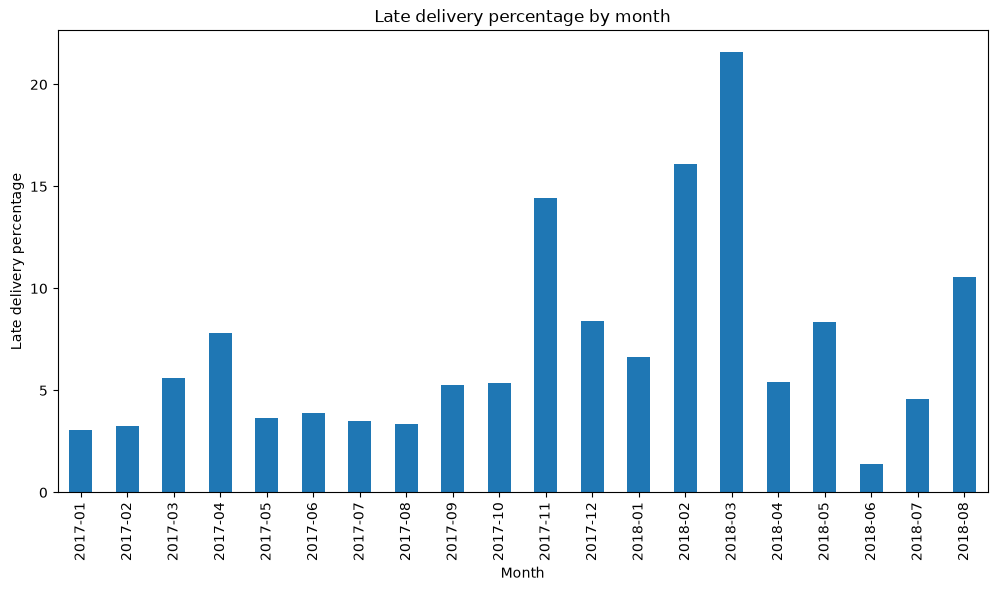

In [13]:
Q1 = run("""
WITH single_seller_orders AS (
    SELECT order_id
    FROM order_items
    GROUP BY order_id
    HAVING COUNT(DISTINCT seller_id) = 1
)
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(*) AS n_orders,
       ROUND(100.0 * SUM(o.order_delivered_customer_date > o.order_estimated_delivery_date) / COUNT(*), 2) AS late_share
FROM orders o
JOIN single_seller_orders x ON x.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2017-01' AND '2018-08'
GROUP BY month
ORDER BY month;
""")
ax = Q1.plot(
    x="month",
    y="late_share",
    kind="bar",
    title="Late delivery percentage by month",
    xlabel="Month",
    ylabel="Late delivery percentage",
    legend=False,
    figsize=(12, 6)
)
ax.figure.savefig("images/Late_delivery_by_month.png")

## Baseline results
- The 20 months interval was split into : train,  before April 2018 (15 months, 63333 orders); A buffer (the month of April 2018); and test, from May 2018 (4 months, 24928 orders).
- Late orders are more frequent for the training set (9.3%) than the test set (6.3%). This might be affected by the months of November 2017, February and March 2018, where the percentage of late orders rose to 14.45% (Black Friday period), 16.08% and 21.57% respectively.
- The random model has a PR AUC of 0.063. Accuracy isn't useful here since always predicting 'on time' is already 93.7% accurate.
- Two main models were tested: the logistic regression which showed a ROC AUC of 0.704, and the gradient boosting which showed a ROC AUC of 0.718. This means that the gradient boosting didn't make a major difference (almost the same ROC AUC score), indicating that the problem might be in the features.
- The PR AUC of both models is 0.13, about twice the random model's. However, this value is still not precise enough to flag late orders confidently.

In [14]:
cut = int(len(X_train) * 0.85)
X_fit, X_val = X_train.iloc[:cut], X_train.iloc[cut:]
y_fit, y_val = y_train.iloc[:cut], y_train.iloc[cut:]

In [15]:
scaler_nn = StandardScaler().fit(X_fit)
X_fit_scaled = scaler_nn.transform(X_fit)
X_val_scaled = scaler_nn.transform(X_val)
X_test_scaled = scaler_nn.transform(X_test)
number_of_columns = X_fit_scaled.shape[1]
print(number_of_columns)

131


In [16]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

def build_model(seed):
    tf.keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(number_of_columns,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy')
    return model

I0000 00:00:1792841955.104189   24660 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792841955.820542   24660 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792841958.132177   24660 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1792841958.697046   24660 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


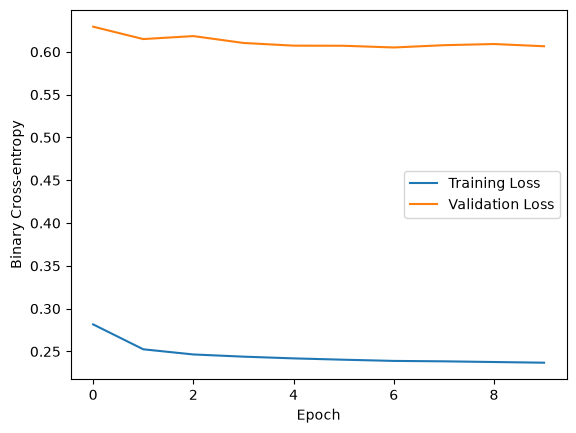

In [17]:
model = build_model(seed=0)
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val), epochs= 50, batch_size=256, callbacks=[early_stop], verbose=0)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-entropy')
plt.legend()
plt.savefig("images/mlp_training_curve.png")
plt.show()

In [18]:
roc_list = []
pr_list = []
for seed in [0, 1, 2]:
    model = build_model(seed)
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val), epochs= 50, batch_size=256, callbacks=[early_stop], verbose=0)
    score = model.predict(X_test_scaled, verbose=0).ravel()
    roc_list.append(roc_auc_score(y_test, score))
    pr_list.append(average_precision_score(y_test, score))
    print(seed, round(roc_list[-1], 3), round(pr_list[-1], 3))

print("average ROC AUC : ", round(sum(roc_list)/len(roc_list), 3))
print("average PR AUC : ", round(sum(pr_list)/len(pr_list), 3))


0 0.634 0.103
1 0.645 0.095
2 0.638 0.092
average ROC AUC :  0.639
average PR AUC :  0.097


In [19]:
from sklearn.metrics import log_loss

print("late rate in validation:", y_val.mean())
print("constant guess, training rate:", log_loss(y_val, [y_fit.mean()] * len(y_val)))
print("constant guess, validation rate:", log_loss(y_val, [y_val.mean()] * len(y_val)))

logreg_nn = LogisticRegression(max_iter=1000).fit(X_fit_scaled, y_fit)
print("logistic regression:", log_loss(y_val, logreg_nn.predict_proba(X_val_scaled)[:, 1]))

late rate in validation: 0.22136842105263158
constant guess, training rate: 0.6452386241694015
constant guess, validation rate: 0.5286344778119759
logistic regression: 0.6109790714702917


## MLP results
- I implemented a Multilayer Perceptron composed of two hidden layers (32 and 16 neurons, with 20% dropout) and a one neuron output layer, and ran it with three seeds. I took the average over the three seeds (ROC AUC between 0.634 and 0.645).
- The validation set is the last 15% of the training period. This means that it is mostly the peak late delivery months of February and March 2018 (validation late rate of 22.1%).
- The MLP with a ROC AUC of 0.639 beats the random model (ROC AUC = 0.5). However, its ranking is worse than the two simple models (Logistic regression : 0.704; Gradient boosting : 0.718).
- In addition, the MLP model got a PR AUC of 0.097, which is higher than the random model's (0.063) but also lower than the two simple models's (0.13 each).

| Model | ROC AUC | PR AUC |
|---|---|---|
| Random | 0.500 | 0.063 |
| Logistic regression | 0.704 | 0.130 |
| Gradient boosting | 0.718 | 0.130 |
| MLP (average of 3 seeds)| 0.639 | 0.097 |

![](images/mlp_training_curve.png)

- The gap between the training loss which goes down to about 0.24, while the validation loss stays flat around 0.60, is huge. Part of this is overfitting, but not all. The validation months have a much higher late rate (22.1%) than most of the training period, and logistic regression has a similar validation loss (0.61). So the model does not carry what it learned from the training period to these months. This is probably because the delays in those months came from causes that the chosen features don't describe.
- The neural network did not beat simpler models, which is common on small tabular datasets.

## Part 2: with seller history

In [20]:
run("""
WITH single_seller_orders AS (
    SELECT i.order_id,
           MIN(i.seller_id) AS seller_id,
           COUNT(*) AS n_items,
           SUM(i.price) AS total_price,
           SUM(i.freight_value) AS total_freight,
           SUM(p.product_weight_g) AS total_weight_g,
           MIN(p.product_category_name) AS category
    FROM order_items i
    JOIN products p ON i.product_id = p.product_id
    GROUP BY i.order_id
    HAVING COUNT(DISTINCT i.seller_id) = 1
)
SELECT o.order_id,
       o.order_purchase_timestamp,
       o.order_delivered_customer_date,
       c.customer_state,
       s.seller_state,
       x.n_items, x.total_price, x.total_freight, x.total_weight_g, x.category, x.seller_id,
       CAST(strftime('%m', o.order_purchase_timestamp) AS INTEGER) AS month,
       CAST(strftime('%w', o.order_purchase_timestamp) AS INTEGER) AS weekday,
       JULIANDAY(o.order_estimated_delivery_date) - JULIANDAY(o.order_purchase_timestamp) AS estimated_days,
       CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END AS is_late
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN single_seller_orders x ON x.order_id = o.order_id
JOIN sellers s ON s.seller_id = x.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2017-01' AND '2018-08'
ORDER BY o.order_purchase_timestamp;
""")

,order_id,order_purchase_timestamp,order_delivered_customer_date,customer_state,seller_state,n_items,total_price,total_freight,total_weight_g,category,seller_id,month,weekday,estimated_days,is_late
0,ec7a019261fce44180373d45b442d78f,2017-01-05 11:56:06,2017-01-11 13:14:05,PR,PR,1,10.90,8.72,200.0,fashion_bolsas_e_acessorios,48efc9d94a9834137efd9ea76b065a38,1,4,26.502708,0
1,b95a0a8bd30aece4e94e81f0591249d8,2017-01-05 12:01:20,2017-01-17 15:38:58,PR,PR,1,10.90,8.72,200.0,automotivo,48efc9d94a9834137efd9ea76b065a38,1,4,38.499074,0
2,38bcb524e1c38c2c1b60600a80fc8999,2017-01-05 12:06:36,2017-01-16 16:05:22,PR,PR,1,2.90,8.72,200.0,pet_shop,48efc9d94a9834137efd9ea76b065a38,1,4,38.495417,0
3,7a18a504c1a4b32d883e68de2e1a7db0,2017-01-05 12:09:08,2017-01-16 15:43:29,PR,PR,1,7.90,8.72,200.0,pet_shop,48efc9d94a9834137efd9ea76b065a38,1,4,38.493657,0
4,6acecf438369055d9243e121045cca74,2017-01-05 12:11:23,2017-01-17 16:06:30,PR,PR,1,9.90,8.72,200.0,pet_shop,48efc9d94a9834137efd9ea76b065a38,1,4,38.492095,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94926,52018484704db3661b98ce838612b507,2018-08-29 12:25:59,2018-08-30 22:48:27,SP,SP,1,63.90,9.20,1500.0,brinquedos,5f2684dab12e59f83bef73ae57724e45,8,3,4.481956,0
94927,0b223d92c27432930dfe407c6aea3041,2018-08-29 14:18:23,2018-08-30 16:24:55,PR,PR,2,418.00,92.96,27100.0,moveis_cozinha_area_de_servico_jantar_e_jardim,67bf6941ba2f1fa1d02c375766bc3e53,8,3,5.403900,0
94928,168626408cb32af0ffaf76711caae1dc,2018-08-29 14:18:28,2018-08-30 16:52:31,MG,MG,1,45.90,15.39,1614.0,beleza_saude,2a84855fd20af891be03bc5924d2b453,8,3,12.403843,0
94929,03ef5dedbe7492bdae72eec50764c43f,2018-08-29 14:52:00,2018-08-30 16:36:59,SP,SP,1,24.90,8.33,450.0,artigos_de_festas,7d7866a99a8656a42c7ff6352a433410,8,3,4.380556,0


In [21]:
sql = open("sql/orders_dataset2.sql").read()
df = pd.read_sql(sql, con)
df.to_csv("data/orders_dataset2.csv", index=False)

In [22]:
df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"])
delivered = pd.to_datetime(df["order_delivered_customer_date"])
df["purchase_month"] = df["order_purchase_timestamp"].dt.year * 12 + df["order_purchase_timestamp"].dt.month
df["delivery_month"] = delivered.dt.year * 12 + delivered.dt.month

In [23]:
monthly = (df.groupby(["seller_id", "delivery_month"])["is_late"]
             .agg(n_orders="count", n_late="sum").reset_index()
             .rename(columns={"delivery_month": "hist_month"})
             .sort_values("hist_month"))
monthly["cum_orders"] = monthly.groupby("seller_id")["n_orders"].cumsum()
monthly["cum_late"] = monthly.groupby("seller_id")["n_late"].cumsum()

In [24]:
df = df.sort_values("purchase_month")
df = pd.merge_asof(df, monthly[["seller_id", "hist_month", "cum_orders", "cum_late"]],
                   left_on="purchase_month", right_on="hist_month",
                   by="seller_id", allow_exact_matches=False)
df = df.reset_index(drop=True)

In [25]:
df["cum_orders"] = df["cum_orders"].fillna(0)
df["cum_late"] = df["cum_late"].fillna(0)
prior = df.loc[df["order_purchase_timestamp"] < "2018-04-01", "is_late"].mean()
df["seller_past_orders"] = df["cum_orders"]
df["seller_past_late_rate"] = (df["cum_late"] + 10 * prior) / (df["cum_orders"] + 10)

In [26]:
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)
df['category'] = df['category'].fillna('unknown')

In [27]:
train = df[df["order_purchase_timestamp"] < "2018-04-01"]
test = df[df["order_purchase_timestamp"] >= "2018-05-01"]
print(len(train), len(test))
print("The mean of 'is_late' in train : ", train["is_late"].mean())
print("The mean of 'is_late' in test : ", test["is_late"].mean())

63333 24928
The mean of 'is_late' in train :  0.09268469834051758
The mean of 'is_late' in test :  0.06310173299101413


In [28]:
numeric = ("n_items", "total_price", "total_freight", "total_weight_g", "estimated_days", "month", "weekday", "same_state", "seller_past_orders", "seller_past_late_rate")
categorical = ("customer_state", "seller_state", "category")
X = pd.get_dummies(df[list(numeric + categorical)], columns=list(categorical))
X['total_weight_g'] = X['total_weight_g'].fillna(train['total_weight_g'].median())
X_train = X.loc[train.index]
X_test = X.loc[test.index]
y_train = train['is_late']
y_test = test['is_late']
print(X_train.shape, X_test.shape)

(63333, 133) (24928, 133)


In [29]:
scaler = StandardScaler().fit(X_train)

In [30]:
log_reg = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)
proba_log_reg = log_reg.predict_proba(scaler.transform(X_test))[:, 1]
gb = HistGradientBoostingClassifier(random_state=0).fit(X_train, y_train)
proba_gb= gb.predict_proba(X_test)[:, 1]

In [31]:
accuracy = 1- y_test.mean()
print("Never late accuracy : ", accuracy)
for name, proba in [("logistic regression", proba_log_reg), ("gradient boosting", proba_gb)]:
    print(name,"ROC AUC : ", round(roc_auc_score(y_test, proba), 3), 
          "PR AUC : ", round(average_precision_score(y_test, proba),3))
print("random PR AUC would be : ", round(y_test.mean(), 3))

Never late accuracy :  0.9368982670089858
logistic regression ROC AUC :  0.674 PR AUC :  0.123
gradient boosting ROC AUC :  0.704 PR AUC :  0.123
random PR AUC would be :  0.063


In [32]:
cut = int(len(X_train) * 0.85)
X_fit, X_val = X_train.iloc[:cut], X_train.iloc[cut:]
y_fit, y_val = y_train.iloc[:cut], y_train.iloc[cut:]

In [33]:
scaler_nn = StandardScaler().fit(X_fit)
X_fit_scaled = scaler_nn.transform(X_fit)
X_val_scaled = scaler_nn.transform(X_val)
X_test_scaled = scaler_nn.transform(X_test)
number_of_columns = X_fit_scaled.shape[1]
print(number_of_columns)

133


In [34]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

def build_model(seed):
    tf.keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(number_of_columns,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy')
    return model

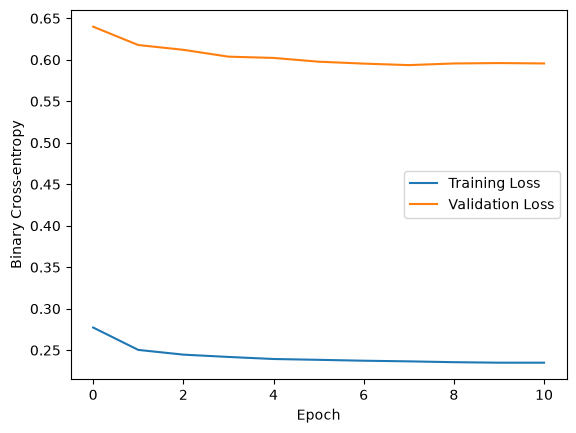

In [35]:
model = build_model(seed=0)
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val), epochs= 50, batch_size=256, callbacks=[early_stop], verbose=0)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-entropy')
plt.legend()
plt.savefig("images/mlp_training_curve2.png")
plt.show()

In [36]:
roc_list = []
pr_list = []
for seed in [0, 1, 2]:
    model = build_model(seed)
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val), epochs= 50, batch_size=256, callbacks=[early_stop], verbose=0)
    score = model.predict(X_test_scaled, verbose=0).ravel()
    roc_list.append(roc_auc_score(y_test, score))
    pr_list.append(average_precision_score(y_test, score))
    print(seed, round(roc_list[-1], 3), round(pr_list[-1], 3))

print("average ROC AUC : ", round(sum(roc_list)/len(roc_list), 3))
print("average PR AUC : ", round(sum(pr_list)/len(pr_list), 3))

0 0.62 0.09
1 0.635 0.096
2 0.605 0.084
average ROC AUC :  0.62
average PR AUC :  0.09


In [37]:
from sklearn.metrics import log_loss

print("late rate in validation:", y_val.mean())
print("constant guess, training rate:", log_loss(y_val, [y_fit.mean()] * len(y_val)))
print("constant guess, validation rate:", log_loss(y_val, [y_val.mean()] * len(y_val)))

logreg_nn = LogisticRegression(max_iter=1000).fit(X_fit_scaled, y_fit)
print("logistic regression:", log_loss(y_val, logreg_nn.predict_proba(X_val_scaled)[:, 1]))

late rate in validation: 0.22136842105263158
constant guess, training rate: 0.6452386241694015
constant guess, validation rate: 0.5286344778119759
logistic regression: 0.5922211513004136


In [38]:
def score_models(numeric):
    categorical = ["customer_state", "seller_state", "category"]
    X = pd.get_dummies(df[numeric + categorical], columns=categorical)
    X["total_weight_g"] = X["total_weight_g"].fillna(train["total_weight_g"].median())
    X_tr, X_te = X.loc[train.index], X.loc[test.index]
    sc = StandardScaler().fit(X_tr)
    lr = LogisticRegression(max_iter=1000).fit(sc.transform(X_tr), train["is_late"])
    gb = HistGradientBoostingClassifier(random_state=0).fit(X_tr, train["is_late"])
    p_lr = lr.predict_proba(sc.transform(X_te))[:, 1]
    p_gb = gb.predict_proba(X_te)[:, 1]
    return [round(f(test["is_late"], p), 3) for p in (p_lr, p_gb) for f in (roc_auc_score, average_precision_score)]

base = ["n_items", "total_price", "total_freight", "total_weight_g",
        "estimated_days", "month", "weekday", "same_state"]
variants = {"no seller features": base,
            "rate only": base + ["seller_past_late_rate"],
            "rate + orders": base + ["seller_past_late_rate", "seller_past_orders"],
            "no month": [c for c in base if c != "month"]}
rows = [[name] + score_models(cols) for name, cols in variants.items()]
print(pd.DataFrame(rows, columns=["features", "LR ROC", "LR PR", "GB ROC", "GB PR"]))

             features  LR ROC  LR PR  GB ROC  GB PR
0  no seller features   0.704  0.130   0.718  0.130
1           rate only   0.696  0.137   0.722  0.135
2       rate + orders   0.674  0.123   0.704  0.123
3            no month   0.701  0.128   0.655  0.100


In [39]:
q, bins = pd.qcut(train["seller_past_late_rate"], 4, retbins=True, duplicates="drop")
bins[0], bins[-1] = -1, 2
print(train.groupby(q, observed=True)["is_late"].mean())
print(test.groupby(pd.cut(test["seller_past_late_rate"], bins), observed=True)["is_late"].mean())

seller_past_late_rate
(0.00393, 0.0356]    0.073828
(0.0356, 0.0535]     0.080790
(0.0535, 0.0812]     0.102227
(0.0812, 0.396]      0.114201
Name: is_late, dtype: float64
seller_past_late_rate
(-1.0, 0.0356]      0.059887
(0.0356, 0.0535]    0.060561
(0.0535, 0.0812]    0.059666
(0.0812, 2.0]       0.066426
Name: is_late, dtype: float64


In [40]:
df[["seller_past_orders", "purchase_month"]].corr()

,seller_past_orders,purchase_month
seller_past_orders,1.000000,0.266848
purchase_month,0.266848,1.000000


## Part 2 results and conclusion

- In this section, I added the sellers history to the features and ran again the same two simple models and the same MLP. However, this did not improve the models on test period.

| Model | Baseline ROC AUC | Baseline PR AUC | Seller history ROC AUC | Seller history PR AUC |
|---|---:|---:|---:|---:|
| Random | 0.500 | 0.063 | 0.500 | 0.063 |
| Logistic regression | 0.704 | 0.130 | 0.674 | 0.123 |
| Gradient boosting | 0.718 | 0.130 | 0.704 | 0.123 |
| MLP (average of 3 seeds)| 0.639 | 0.097 | 0.620 | 0.090 |

![](images/mlp_training_curve2.png)

- In training, orders from sellers with a worse history are more often late (7.4% to 11.4%). In test period the late rate is almost flat (6.0% to 6.6%). This means that the relationship that the models learn doesn't hold in the test months. This suggests that lateness might possibly be driven by events that hit all sellers, like the Black Friday and February-March delays, and not by persistently slow sellers.

| Seller late rate quartile | Late rate in train | Late rate in test |
|---|---|---|
| Lowest | 7.4% | 6.0% |
| Second | 8.1% | 6.1% |
| Third | 10.2% | 6.0% |
| Highest | 11.4% | 6.6% |

- The logistic regression's validation loss did improve a bit (from 0.611 to 0.592). So, the feature helps on the February-March validation months but not on the test months.
- As a result, I chose the first feature set without seller history as my final model. The table below shows that the seller late rate alone was about neutral, and that the 'seller_past_orders' caused the damage.

| features | LR ROC | LR PR | GB ROC | GB PR |
|---|---|---|---|---|
| no seller features | 0.704 | 0.130 | 0.718 | 0.130 |
| rate only | 0.696 | 0.137 | 0.722 | 0.135 |
| rate + orders | 0.674 | 0.123 | 0.704 | 0.123 |
| no month | 0.701 | 0.128 | 0.655 | 0.100 |

- The positif result of the correlation test between 'seller_past_orders' and 'purchase_month' (0.27) confirms that the number of past orders only grows over time, and the models can learn the training period’s events from it instead of learning about sellers.

- To conclude, with only 20 months the models can't tell seasonality from one time events. Also, the test data was studied several times to compare different models.

